# 1 · Data, features and regimes

Reads the Bloomberg export, cleans it, builds every feature, fits the rolling out-of-sample HMMs and writes one table,
`features`, to the project database `data/spx.db`. Notebooks 2 and 3 read only from that database.

In [1]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from hmmlearn.hmm import GaussianHMM
from scipy.special import logsumexp
from scipy.stats import multivariate_normal
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.preprocessing import StandardScaler

sns.set_style('darkgrid')
pd.set_option('display.width', 160)

In [2]:
# ---- configuration ----
DATA_PATH     = '../data/data.csv'
DB_PATH       = '../data/spx.db'
SAMPLE_START  = None            # e.g. '2017-01-01' to use only the post-break sample
PANDEMIC      = ('2020-03-01', '2022-12-31')
OUTLIER_WIN   = 252             # past window for outlier quantiles
OUTLIER_Q     = 0.01
HMM_WINDOW    = 756             # ~3 years
HMM_STEP      = 21              # refit monthly
K_HMM         = 2
SEED          = 42

## 1.1 Load and clean

In [3]:
df = pd.read_csv(DATA_PATH, encoding='utf-8-sig')
if np.issubdtype(df['Dates'].dtype, np.number):
    df['Date'] = pd.to_datetime(df['Dates'], unit='D', origin='1899-12-30')   # Excel serial
else:
    df['Date'] = pd.to_datetime(df['Dates'])
df = df.sort_values('Date').set_index('Date')

df = df.dropna(subset=['PX_BID', 'PX_ASK', 'PX_MID', 'PX_LAST', 'PX_VOLUME'])
valid = (df['PX_ASK'] > df['PX_BID']) & (df['PX_BID'] <= df['PX_MID']) & (df['PX_MID'] <= df['PX_ASK'])
print(f"Invalid quotes removed (data errors): {(~valid).sum()} of {len(df)}")
df = df[valid].copy()

# exchange holidays are filled by the vendor with a verbatim copy of the previous day -> not real observations
stale = (df['PX_LAST'].diff() == 0) & (df['PX_VOLUME'].diff() == 0) & (df['PX_BID'].diff() == 0)
print(f"Stale holiday rows removed (copy of previous day): {stale.sum()}, e.g. {df.index[stale][:3].strftime('%Y-%m-%d').tolist()}")
df = df[~stale].copy()
if SAMPLE_START is not None:
    df = df.loc[SAMPLE_START:].copy()
print("Date range:", df.index.min().date(), "to", df.index.max().date(), "| rows:", len(df))
print("Gaps between rows (calendar days):", df.index.to_series().diff().dt.days.value_counts().sort_index().to_dict())

Invalid quotes removed (data errors): 1 of 7229
Stale holiday rows removed (copy of previous day): 256, e.g. ['1998-04-10', '1998-05-25', '1998-07-03']
Date range: 1998-03-02 to 2025-11-13 | rows: 6972
Gaps between rows (calendar days): {1.0: 5460, 2.0: 66, 3.0: 1258, 4.0: 184, 5.0: 2, 6.0: 1}


## 1.2 Features

Built on the contiguous series, no rows deleted. Every predictor used by the forecasting models is known at the close of day t-1.
The forecasting target is `log_y = log(rel_spread)`.

NaNs before ffill: 1220
Rows flagged as outliers (excluded from training only): 527


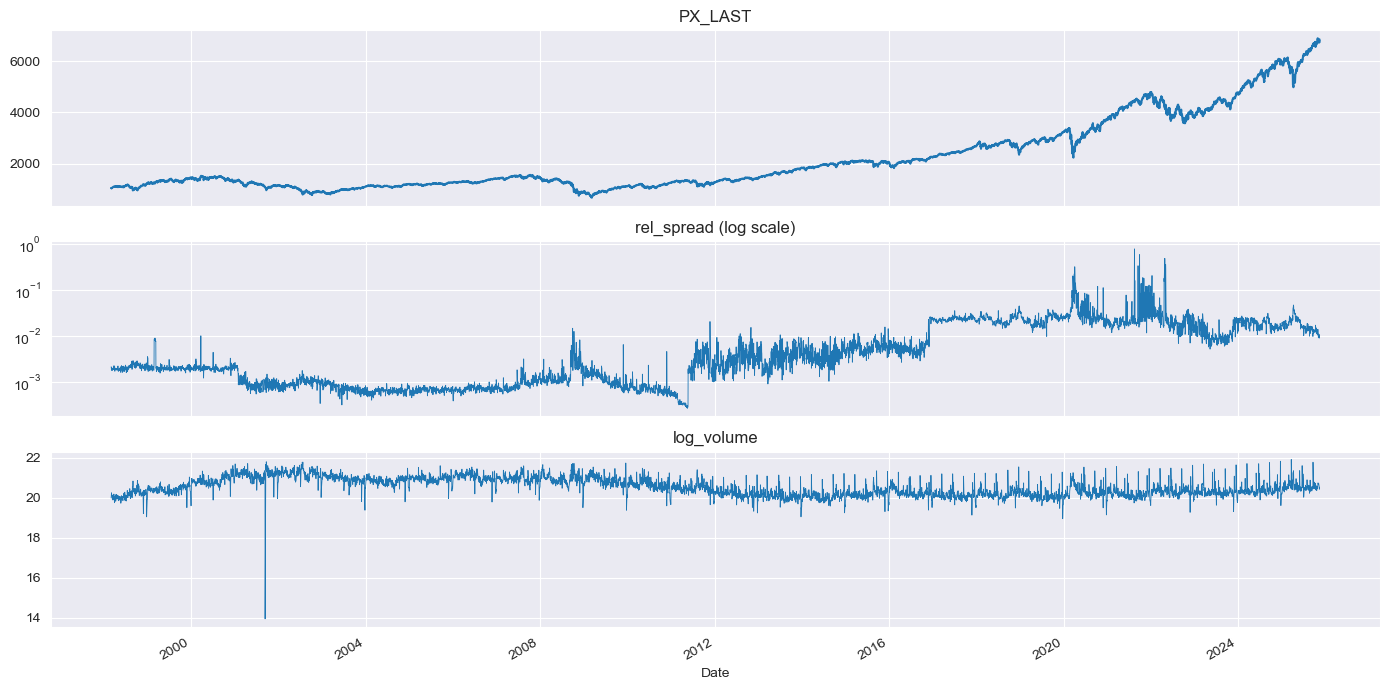

In [4]:
df['return']     = df['PX_LAST'] / df['PX_CLOSE_1D'] - 1
df['abs_return'] = df['return'].abs()
df['rel_spread'] = (df['PX_ASK'] - df['PX_BID']) / df['PX_MID']
df['log_volume'] = np.log(df['PX_VOLUME'].where(df['PX_VOLUME'] > 0))
df['pe_diff']    = df['BEST_PE_RATIO'].diff()
df['ami']        = df['abs_return'] / df['PX_VOLUME'] * 1e9          # Amihud: |r_t| / Vol_t (scaled)

# already lagged (use information up to t-1)
df['rv_5']         = df['return'].shift(1).rolling(5, min_periods=3).std() * np.sqrt(252)
df['rv_21']        = df['return'].shift(1).rolling(21, min_periods=10).std() * np.sqrt(252)
df['price_trend']  = df['PX_LAST'].shift(1).rolling(5).mean() / df['PX_LAST'].shift(1).rolling(20).mean() - 1
df['volume_trend'] = df['PX_VOLUME'].shift(1).rolling(5).mean() / df['PX_VOLUME'].shift(1).rolling(20).mean() - 1
for l in [1, 2, 3, 5]:
    df[f'spread_lag{l}'] = df['rel_spread'].shift(l)
for c in ['log_volume', 'ami', 'pe_diff']:
    df[f'{c}_lag1'] = df[c].shift(1)

df['pandemic_dummy'] = ((df.index >= PANDEMIC[0]) & (df.index <= PANDEMIC[1])).astype(int)

# HAR-style long-memory features: average log spread over the past 5 / 22 / 63 days (known at t-1)
for w in [5, 22, 63]:
    df[f'har_{w}'] = np.log(df['rel_spread']).shift(1).rolling(w).mean()

# calendar features (the exchange calendar is known in advance, so using the next trading date is not look-ahead)
dates = df.index.to_series()
gap_next, gap_prev = (dates.shift(-1) - dates).dt.days, (dates - dates.shift(1)).dt.days
wd = df.index.weekday
df['pre_holiday']  = (((wd < 4) & (gap_next > 1)) | ((wd == 4) & (gap_next > 3))).astype(int)
df['post_holiday'] = (((wd > 0) & (gap_prev > 1)) | ((wd == 0) & (gap_prev > 3))).astype(int)
month = df.index.to_period('M').to_series(index=df.index)
df['month_end']    = (month != month.shift(-1)).astype(int)
df['month_start']  = (month != month.shift(1)).astype(int)
third_friday = (wd == 4) & (df.index.day >= 15) & (df.index.day <= 21)
df['opex']          = third_friday.astype(int)
df['quad_witching'] = (third_friday & df.index.month.isin([3, 6, 9, 12])).astype(int)
for k, name in enumerate(['mon', 'tue', 'wed', 'thu']):
    df[f'dow_{name}'] = (wd == k).astype(int)

# causal fill only (no two-sided interpolation)
num_cols = df.select_dtypes('number').columns
print("NaNs before ffill:", int(df[num_cols].isna().sum().sum()))
df[num_cols] = df[num_cols].ffill()

# outlier flags from PAST quantiles only; used to exclude rows from training, never from testing
def past_quantile_flag(s, win=OUTLIER_WIN, q=OUTLIER_Q):
    past = s.shift(1).rolling(win, min_periods=win // 2)
    return (s < past.quantile(q)) | (s > past.quantile(1 - q))

df['spread_outlier'] = past_quantile_flag(df['rel_spread'])
df['volume_outlier'] = past_quantile_flag(df['log_volume'])
df['train_ok'] = ~(df['spread_outlier'] | df['volume_outlier'])
print(f"Rows flagged as outliers (excluded from training only): {(~df['train_ok']).sum()}")

# modelling target and log lags
df['y'] = df['rel_spread']
df['log_y'] = np.log(df['y'])
df['log_spread_lag1'] = np.log(df['spread_lag1'])
df['log_spread_lag2'] = np.log(df['spread_lag2'])

fig, axes = plt.subplots(3, 1, figsize=(14, 7), sharex=True)
df['PX_LAST'].plot(ax=axes[0], title='PX_LAST')
df['rel_spread'].plot(ax=axes[1], title='rel_spread (log scale)', logy=True, lw=0.6)
df['log_volume'].plot(ax=axes[2], title='log_volume', lw=0.6)
plt.tight_layout(); plt.show()

## 1.3 Level shifts in the index quote

The level of `rel_spread` jumps roughly 6x in June 2011 and 4x in December 2016, within a single month each time.
SPX liquidity did not deteriorate like that, so these jumps most likely reflect changes in how the data vendor computes the index bid/ask.
Set `SAMPLE_START` (e.g. `'2017-01-01'`) for a post-break robustness check.

In [5]:
yearly = df.groupby(df.index.year)['rel_spread'].agg(['median', 'mean', 'count'])
print(yearly.round(5).to_string())

monthly = df['rel_spread'].resample('ME').median()
ratio = (monthly / monthly.shift(1)).dropna()
print("Largest month-over-month jumps in median rel_spread:")
print(ratio.sort_values(ascending=False).head(3).round(2).to_string())

       median     mean  count
Date                         
1998  0.00208  0.00211    213
1999  0.00197  0.00226    252
2000  0.00195  0.00202    252
2001  0.00092  0.00101    249
2002  0.00097  0.00097    252
2003  0.00075  0.00076    252
2004  0.00063  0.00064    252
2005  0.00067  0.00067    252
2006  0.00069  0.00071    251
2007  0.00083  0.00091    251
2008  0.00119  0.00182    253
2009  0.00111  0.00121    252
2010  0.00068  0.00072    252
2011  0.00172  0.00213    252
2012  0.00304  0.00363    250
2013  0.00345  0.00382    252
2014  0.00370  0.00399    251
2015  0.00569  0.00595    252
2016  0.00534  0.00700    252
2017  0.02338  0.02355    251
2018  0.02267  0.02337    251
2019  0.02305  0.02307    252
2020  0.02657  0.03903    253
2021  0.02052  0.03843    252
2022  0.02201  0.03471    251
2023  0.01021  0.01232    250
2024  0.01876  0.01907    252
2025  0.01662  0.01830    218
Largest month-over-month jumps in median rel_spread:
Date
2011-06-30    6.34
2021-10-31    3.88
2016

## 1.4 K-means (exploratory, in-sample, outlier days excluded — not used for forecasting)

Features: ['rv_5', 'log_volume', 'rel_spread', 'ami', 'pe_diff', 'price_trend'] | best K (silhouette) = 5


Silhouette 0.250 | Davies-Bouldin 1.322 | Calinski-Harabasz 1210.1


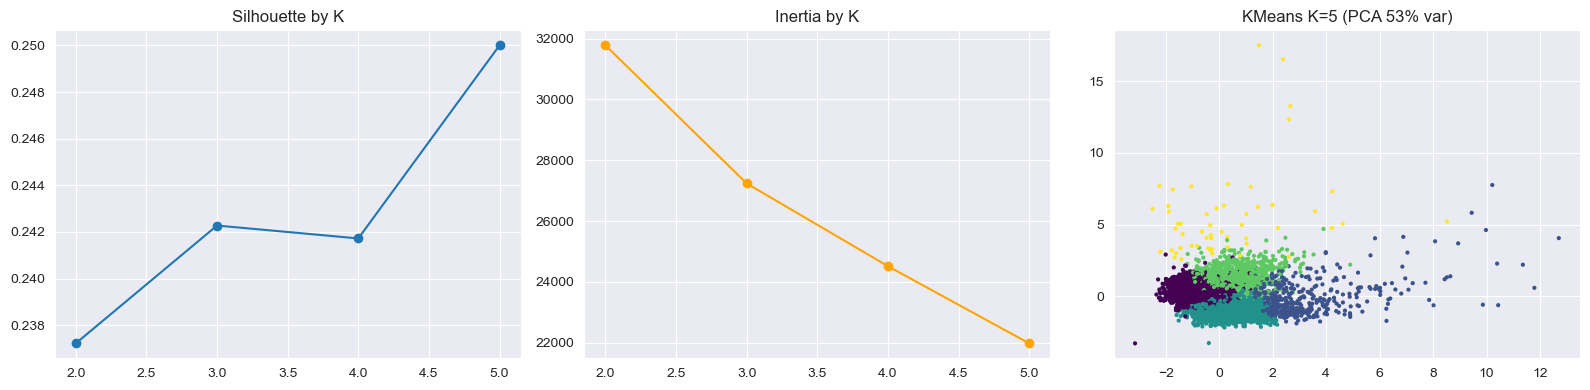

,rv_5,log_volume,rel_spread,ami,pe_diff,price_trend
cluster,,,,,,
0,0.105948,20.179699,0.012599,0.006218,-0.001466,0.009308
1,0.424688,20.937500,0.006505,0.013766,0.059928,-0.038692
2,0.151527,20.942779,0.001516,0.005374,-0.012581,0.004133
3,0.174630,20.331769,0.012550,0.022583,0.012966,-0.001843
4,0.257549,20.341002,0.126254,0.017718,0.091217,0.004217


In [6]:
cluster_features = ['rv_5', 'log_volume', 'rel_spread', 'ami', 'pe_diff', 'price_trend']
X_cluster = df.loc[df['train_ok'], cluster_features].dropna()

corr = X_cluster.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
drop = [c for c in upper.columns if (upper[c] > 0.8).any()]
cluster_opt = [f for f in cluster_features if f not in drop]
Xs = StandardScaler().fit_transform(X_cluster[cluster_opt])

K_list = [2, 3, 4, 5]
sil, inertia = [], []
for k in K_list:
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10).fit(Xs)
    sil.append(silhouette_score(Xs, km.labels_)); inertia.append(km.inertia_)
best_k = K_list[int(np.argmax(sil))]

km = KMeans(n_clusters=best_k, random_state=SEED, n_init=10).fit(Xs)
labels_km = km.labels_
print(f"Features: {cluster_opt} | best K (silhouette) = {best_k}")
print(f"Silhouette {silhouette_score(Xs, labels_km):.3f} | Davies-Bouldin {davies_bouldin_score(Xs, labels_km):.3f} "
      f"| Calinski-Harabasz {calinski_harabasz_score(Xs, labels_km):.1f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(K_list, sil, marker='o'); axes[0].set_title('Silhouette by K')
axes[1].plot(K_list, inertia, marker='o', color='orange'); axes[1].set_title('Inertia by K')
pca = PCA(n_components=2).fit(Xs); P = pca.transform(Xs)
axes[2].scatter(P[:, 0], P[:, 1], c=labels_km, s=4, cmap='viridis')
axes[2].set_title(f'KMeans K={best_k} (PCA {pca.explained_variance_ratio_.sum():.0%} var)')
plt.tight_layout(); plt.show()

display(X_cluster[cluster_opt].assign(cluster=labels_km).groupby('cluster').mean())

## 1.5 Rolling out-of-sample HMM

For each refit date *i*: fit on `[i-W, i)`, then run the forward filter over `[i-W, i+STEP)` and keep rows `[i, i+STEP)`.
P(state at t) therefore only uses observations up to t, and the model never saw those rows during fitting.
States are relabelled by the fitted mean of the spread feature (state 0 = low spread, state 1 = high spread).

In [7]:
def filtered_probs(model, X):
    # forward algorithm: P(s_t | x_1..x_t)
    logB = np.column_stack([multivariate_normal(model.means_[k], model.covars_[k], allow_singular=True).logpdf(X)
                            for k in range(model.n_components)])
    with np.errstate(divide='ignore'):                    # log(0) = -inf is fine here
        logA, logpi = np.log(model.transmat_), np.log(model.startprob_)
    out = np.empty_like(logB)
    la = logpi + logB[0]
    out[0] = la - logsumexp(la)
    for t in range(1, len(X)):
        la = logsumexp(out[t - 1][:, None] + logA, axis=0) + logB[t]
        out[t] = la - logsumexp(la)
    return np.exp(out)


def run_hmm(F, K=K_HMM, sort_col=0, window=HMM_WINDOW, step=HMM_STEP):
    # rolling out-of-sample HMM; returns filtered P(state_t | x_1..x_t), states sorted by the mean of column sort_col
    F = F.dropna()
    X, n = F.values, len(F)
    P = np.full((n, K), np.nan)
    transmats, n_fail = [], 0
    for i in range(window, n, step):
        end = min(i + step, n)
        scaler = StandardScaler().fit(X[i - window:i])
        train = scaler.transform(X[i - window:i])
        try:
            m = GaussianHMM(n_components=K, covariance_type='full', n_iter=200, random_state=SEED).fit(train)
        except Exception as e:
            n_fail += 1
            print(f"HMM fit failed at {F.index[i].date()}: {e}")
            continue
        order = np.argsort(m.means_[:, sort_col])
        P[i:end] = filtered_probs(m, scaler.transform(X[i - window:end]))[window:][:, order]
        transmats.append(m.transmat_[np.ix_(order, order)])
    # sanity check: forward filter at the last step equals hmmlearn's smoothed posterior at the last step
    assert np.allclose(filtered_probs(m, train)[-1], m.predict_proba(train)[-1], atol=1e-6)
    return pd.DataFrame(P, index=F.index, columns=[f'prob_state_{k}' for k in range(K)]), transmats, n_fail


df['log_rel_spread'] = np.log(df['rel_spread'])
df['log_rv_5']       = np.log(df['rv_5'].clip(lower=1e-3))   # rv_5 can be exactly 0
df['log_ami']        = np.log(df['ami'] + 1e-3)
hmm_features = ['log_rel_spread', 'log_rv_5', 'log_volume', 'log_ami', 'price_trend']

probs, transmats, n_fail = run_hmm(df[hmm_features])
df[probs.columns] = probs
P = df[[f'prob_state_{k}' for k in range(K_HMM)]]
df['hmm_state'] = np.where(P.notna().all(axis=1), P.fillna(-1).values.argmax(axis=1), np.nan)
# prob_state_0 is not used as a predictor: it equals 1 - prob_state_1 (perfect collinearity)
df['prob_state_1_lag1'] = df['prob_state_1'].shift(1)

print(f"Windows: {len(transmats)} fitted, {n_fail} failed | rows with OOS state: {df['hmm_state'].notna().sum()}")
print("Average transition matrix across windows:\n", np.mean(transmats, axis=0).round(3))
display(df.groupby('hmm_state')[['rel_spread', 'rv_5', 'log_volume']].agg(['mean', 'median', 'count']))

period = pd.cut(df.index.year, bins=5, labels=['P1', 'P2', 'P3', 'P4', 'P5'])
print("State share by period:")
print(df.assign(period=period).dropna(subset=['hmm_state']).groupby('period', observed=True)['hmm_state']
        .value_counts(normalize=True).unstack(fill_value=0).round(3))

Windows: 296 fitted, 0 failed | rows with OOS state: 6196
Average transition matrix across windows:
 [[0.954 0.046]
 [0.057 0.943]]


rel_spread                      rv_5                 log_volume                 
                mean    median count      mean    median count       mean     median count
hmm_state                                                                                 
0.0         0.006891  0.001017  3129  0.131155  0.112316  3129  20.622482  20.606011  3129
1.0         0.014715  0.005990  3067  0.176143  0.138366  3067  20.430866  20.331948  3067

State share by period:


hmm_state    0.0    1.0
period                 
P1         0.984  0.016
P2         0.520  0.480
P3         0.426  0.574
P4         0.304  0.696
P5         0.519  0.481


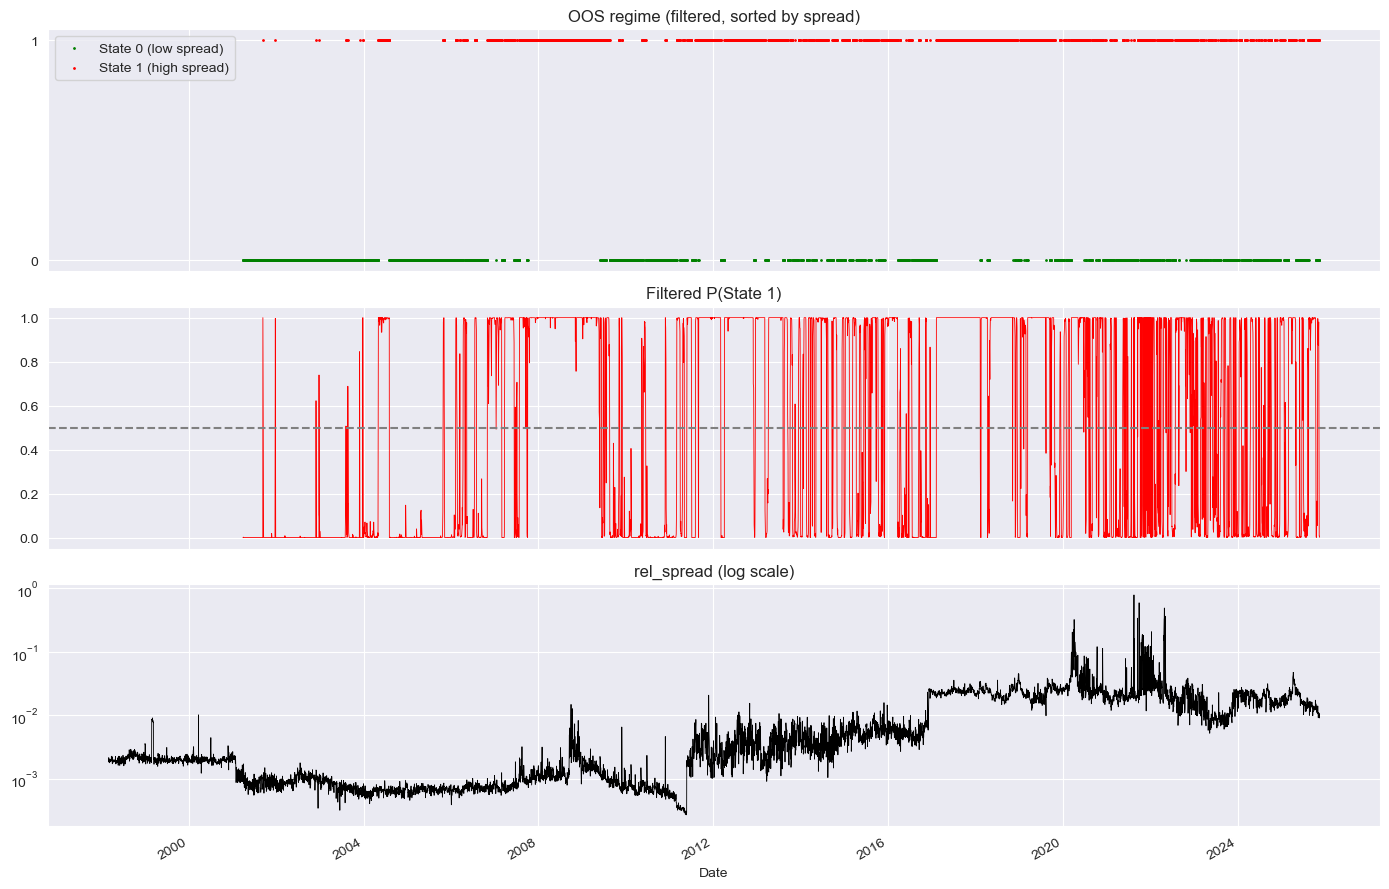

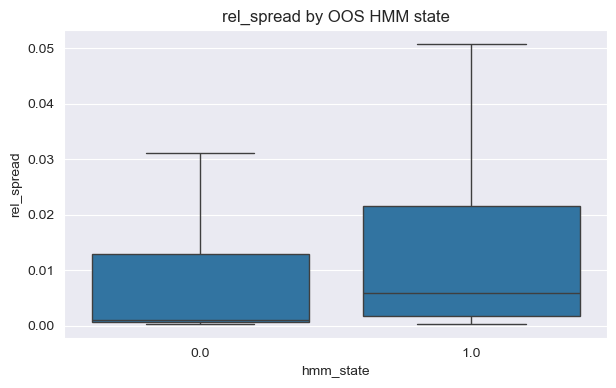

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
for k, c, lab in [(0, 'green', 'State 0 (low spread)'), (1, 'red', 'State 1 (high spread)')]:
    s = df.index[df['hmm_state'] == k]
    axes[0].scatter(s, [k] * len(s), c=c, s=1, label=lab)
axes[0].set_yticks([0, 1]); axes[0].legend(loc='upper left'); axes[0].set_title('OOS regime (filtered, sorted by spread)')
df['prob_state_1'].plot(ax=axes[1], color='red', lw=0.6); axes[1].axhline(0.5, ls='--', c='gray')
axes[1].set_title('Filtered P(State 1)')
df['rel_spread'].plot(ax=axes[2], color='black', lw=0.6, logy=True); axes[2].set_title('rel_spread (log scale)')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(x='hmm_state', y='rel_spread', data=df.dropna(subset=['hmm_state']), ax=ax, showfliers=False)
ax.set_title('rel_spread by OOS HMM state'); plt.show()

## 1.6 Alternative HMM inputs (for the robustness checks)

* **local-z** — each HMM input is standardised against its own past 63 days, so states capture *local* stress rather than
  the data-vendor eras;
* **dynamics** — the HMM sees Δ log spread, |return| and Δ log volume, i.e. information that is not already a regressor.

In [9]:
def local_z(s, w=63):
    return (s - s.shift(1).rolling(w).mean()) / s.shift(1).rolling(w).std()

hmm_inputs = {
    'local_z': pd.DataFrame({c: local_z(df[c]) for c in ['log_rel_spread', 'log_rv_5', 'log_volume', 'log_ami']})
                 .assign(price_trend=df['price_trend']),
    'dynamics': pd.DataFrame({'dlog_spread': df['log_rel_spread'].diff(), 'abs_return': df['abs_return'],
                              'dlog_volume': df['log_volume'].diff()}),
}
for key, F in hmm_inputs.items():
    P_v, _, _ = run_hmm(F)
    df[f'hmm_{key}_lag1'] = P_v['prob_state_1'].shift(1).reindex(df.index)
    print(f"{key}: {df[f'hmm_{key}_lag1'].notna().sum()} days with a lagged OOS probability")

local_z: 6149 days with a lagged OOS probability


dynamics: 6214 days with a lagged OOS probability


## 1.7 Spike target

A spike is a day whose log spread exceeds the 90th percentile of the **previous** 252 days. `spike_lag1` and `dist_to_thr`
(yesterday's distance to today's threshold) are the naive predictors.

In [10]:
spike_thr = df['log_rel_spread'].shift(1).rolling(252, min_periods=126).quantile(0.9)
df['spike'] = (df['log_rel_spread'] > spike_thr).astype(float).where(spike_thr.notna())
df['spike_lag1'] = df['spike'].shift(1)
df['dist_to_thr'] = df['log_rel_spread'].shift(1) - spike_thr
print(f"Spike rate: {df['spike'].mean():.3f}")

Spike rate: 0.136

## 1.8 Write to the database

In [11]:
out = df.drop(columns=['Dates']).copy()
for c in out.select_dtypes('bool').columns:
    out[c] = out[c].astype(int)
out.index = out.index.strftime('%Y-%m-%d')

with sqlite3.connect(DB_PATH) as con:
    out.to_sql('features', con, if_exists='replace', index=True, index_label='date')
    n, k = con.execute('select count(*) from features').fetchone()[0], len(out.columns)
print(f"features: {n} rows x {k} columns -> {DB_PATH}")

features: 6972 rows x 61 columns -> ../data/spx.db
